In [2]:
import numpy as np, pandas as pd, shap, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from lightgbm import LGBMClassifier
import warnings; warnings.filterwarnings("ignore")

df = pd.read_excel("WQD.xlsx")
TARGET = "Water Quality"
X, y = df.drop(columns=[TARGET]), df[TARGET]
features = list(X.columns)
class_names = ["Excellent", "Good", "Poor"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)
Xtr = pd.DataFrame(scaler.transform(X_train), columns=features)
Xte = pd.DataFrame(scaler.transform(X_test),  columns=features)
print(df.shape, Xtr.shape, Xte.shape)

C:\Users\krrag\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(4300, 15) (2881, 14) (1419, 14)


In [3]:
model14 = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                         random_state=42, n_jobs=-1, verbose=-1).fit(Xtr, y_train)
print("14-feature accuracy:", round(accuracy_score(y_test, model14.predict(Xte)), 4))

14-feature accuracy: 0.9965


In [4]:
sv = shap.TreeExplainer(model14).shap_values(Xte)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv   # (samples, features, classes)
print(sv.shape)   # expect (1419, 14, 3)

(1419, 14, 3)


In [5]:
mean_abs = np.abs(sv).mean(axis=0)                      # (features, classes)
phi = pd.DataFrame(mean_abs / mean_abs.sum(axis=0), index=features, columns=class_names)
phi["Overall"] = np.abs(sv).mean(axis=(0, 2))
phi["Overall"] /= phi["Overall"].sum()
phi = phi.sort_values("Overall", ascending=False)
phi["Rank"] = range(1, len(phi) + 1)
drop = ("pH", "Hardness", "Calcium", "Plankton", "Phosphorus")
phi["Kept_in_9"] = ~phi.index.str.startswith(drop)
phi["Cumulative"] = phi["Overall"].cumsum()
print(phi.round(4).to_string())
phi.to_csv("shap_feature_ranking.csv")

                      Excellent    Good    Poor  Overall  Rank  Kept_in_9  Cumulative
H2S (mg L-1 )            0.0416  0.3399  0.0455   0.1498     1       True      0.1498
Nitrite (mg L-1 )        0.2144  0.0791  0.0647   0.1243     2       True      0.2742
DO(mg/L)                 0.1355  0.1295  0.0830   0.1188     3       True      0.3930
Turbidity (cm)           0.1173  0.1443  0.0786   0.1163     4       True      0.5093
Ammonia (mg L-1 )        0.1946  0.0937  0.0416   0.1160     5       True      0.6252
BOD (mg/L)               0.1351  0.1040  0.1044   0.1154     6       True      0.7407
Alkalinity (mg L-1 )     0.0144  0.0070  0.2185   0.0683     7       True      0.8089
Temp                     0.0688  0.0350  0.0809   0.0600     8       True      0.8690
CO2                      0.0539  0.0279  0.0873   0.0538     9       True      0.9228
pH`                      0.0063  0.0113  0.0461   0.0191    10      False      0.9419
Calcium (mg L-1 )        0.0079  0.0070  0.0364   0.01

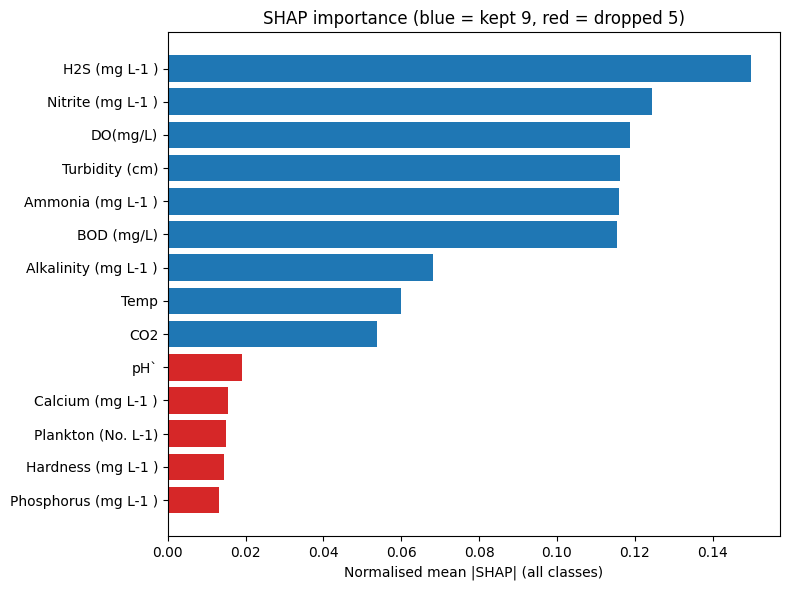

In [6]:
order = phi.index[::-1]
colors = ["tab:blue" if k else "tab:red" for k in phi.loc[order, "Kept_in_9"]]
plt.figure(figsize=(8, 6))
plt.barh(order, phi.loc[order, "Overall"], color=colors)
plt.xlabel("Normalised mean |SHAP| (all classes)")
plt.title("SHAP importance (blue = kept 9, red = dropped 5)")
plt.tight_layout(); plt.savefig("shap_bar_9_vs_5.png", dpi=300); plt.show()

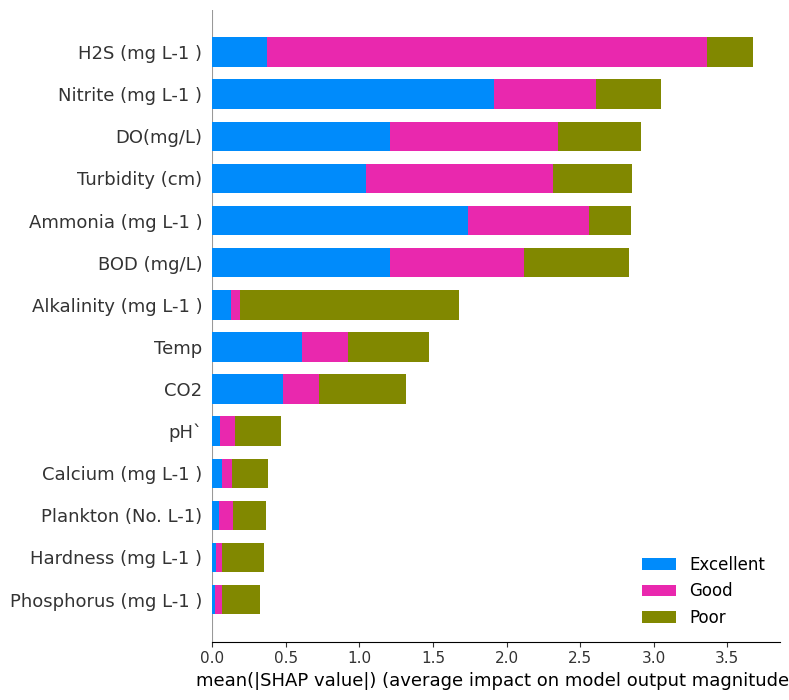

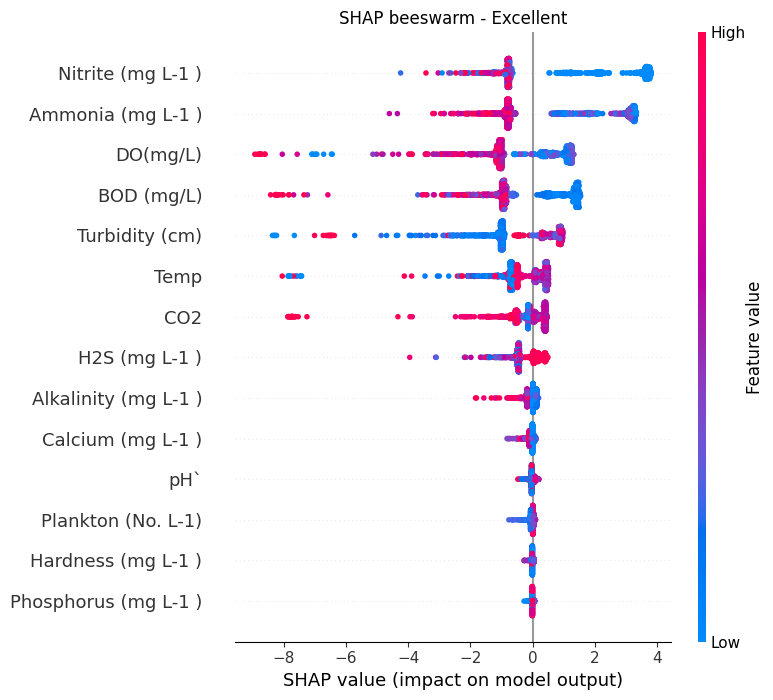

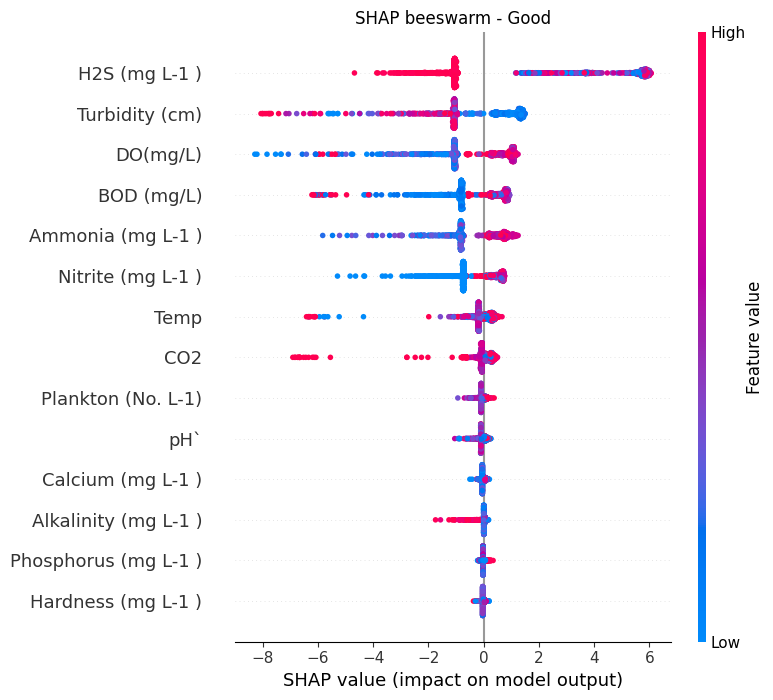

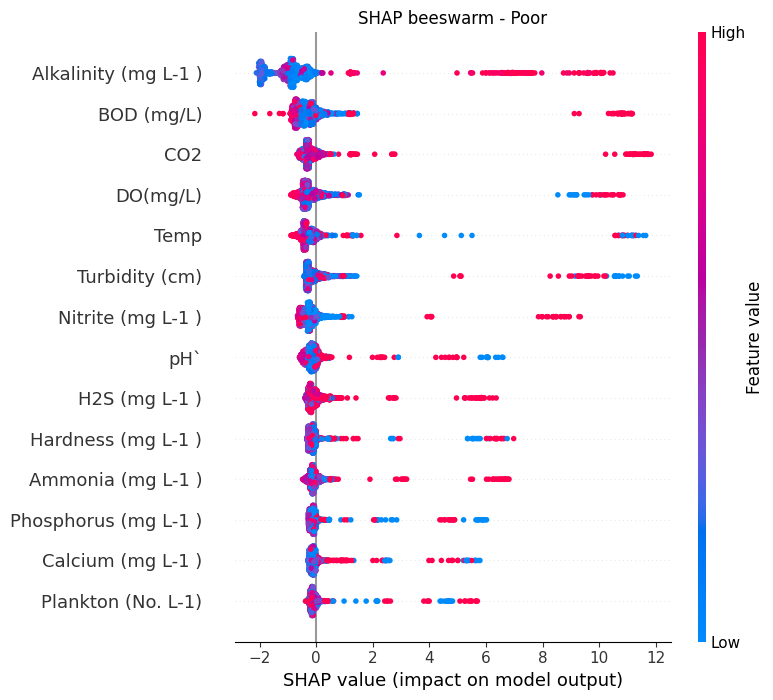

In [7]:
shap.summary_plot([sv[:, :, c] for c in range(3)], Xte,
                  class_names=class_names, plot_type="bar", show=False)
plt.tight_layout(); plt.savefig("shap_summary_bar.png", dpi=300); plt.show()

for c, name in enumerate(class_names):
    shap.summary_plot(sv[:, :, c], Xte, show=False)
    plt.title(f"SHAP beeswarm - {name}")
    plt.tight_layout(); plt.savefig(f"shap_beeswarm_{name}.png", dpi=300); plt.show()

In [8]:
for k in range(3, 15):
    top = list(phi.index[:k])
    m = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                       random_state=42, n_jobs=-1, verbose=-1).fit(Xtr[top], y_train)
    print(f"top-{k:2d} features  acc = {accuracy_score(y_test, m.predict(Xte[top])):.4f}")

top- 3 features  acc = 0.7907
top- 4 features  acc = 0.8569
top- 5 features  acc = 0.8739
top- 6 features  acc = 0.9084
top- 7 features  acc = 0.9098
top- 8 features  acc = 0.9521
top- 9 features  acc = 0.9958
top-10 features  acc = 0.9958
top-11 features  acc = 0.9944
top-12 features  acc = 0.9965
top-13 features  acc = 0.9965
top-14 features  acc = 0.9965


In [9]:
features_9 = [f for f in features if not f.startswith(drop)]
print(len(features_9), features_9)

lgbm_9 = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                        random_state=42, n_jobs=-1, verbose=-1
                        ).fit(Xtr[features_9], y_train)

pred = lgbm_9.predict(Xte[features_9])
print("9-feature accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=class_names))

joblib.dump(lgbm_9, "lgbm_9_features.joblib")
joblib.dump(features_9, "features_9.joblib")
joblib.dump(scaler, "scaler_14.joblib")

9 ['Temp', 'Turbidity (cm)', 'DO(mg/L)', 'BOD (mg/L)', 'CO2', 'Alkalinity (mg L-1 )', 'Ammonia (mg L-1 )', 'Nitrite (mg L-1 )', 'H2S (mg L-1 )']
9-feature accuracy: 0.9951
              precision    recall  f1-score   support

   Excellent       0.99      1.00      1.00       462
        Good       0.99      1.00      1.00       462
        Poor       1.00      0.99      0.99       495

    accuracy                           1.00      1419
   macro avg       0.99      1.00      1.00      1419
weighted avg       1.00      1.00      1.00      1419



['scaler_14.joblib']

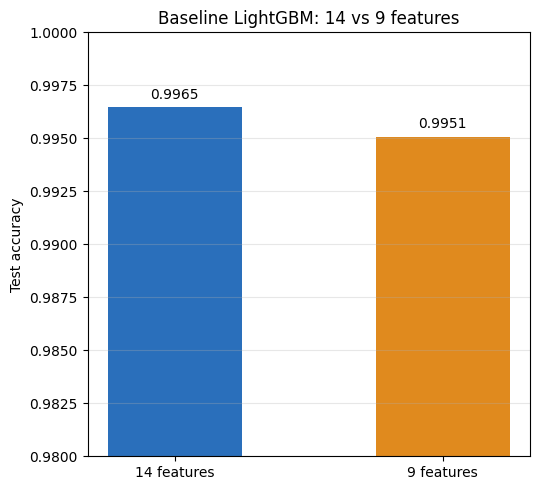

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

acc_14 = accuracy_score(y_test, base14.predict(Xte))
acc_9  = accuracy_score(y_test, base9.predict(Xte[features_9]))

fig, ax = plt.subplots(figsize=(5.5, 5))
bars = ax.bar(["14 features", "9 features"], [acc_14, acc_9],
              color=["#2a6fbb", "#e08a1e"], width=0.5)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.0004,
            f"{b.get_height():.4f}", ha="center", fontsize=10)
ax.set_ylim(0.98, 1.0)
ax.set_ylabel("Test accuracy")
ax.set_title("Baseline LightGBM: 14 vs 9 features")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("baseline_14_vs_9_clean.png", dpi=300)
plt.show()